In [1]:
import numpy as np
import pandas as pd

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

from pathlib import Path
from rasterio.enums import Resampling
from rasterio.windows import Window

%matplotlib inline

plt.rcParams.update({
    "font.size": 12,
    "figure.dpi": 120,
    "axes.grid": False
})

print("Rasterio:", rasterio.__version__)
print("Libraries imported successfully.")

Rasterio: 1.5.2
Libraries imported successfully.


# Define the project directories

In [3]:
# Locate project directory

ROOT = Path.cwd().resolve()

if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
NOTEBOOK_DIR = ROOT / "notebooks"

print("Project root:", ROOT)
print("Data directory:", DATA_DIR)
print("Data directory exists:", DATA_DIR.exists())

Project root: /Users/sourabh/Documents/python_codes/venus_clus
Data directory: /Users/sourabh/Documents/python_codes/venus_clus/data
Data directory exists: True


In [4]:
FILES = {
    "Emissivity": DATA_DIR / "Venus_Magellan_MicrowaveEmissivity_Global_4641m.tif",

    "Reflectivity": DATA_DIR / "Venus_Magellan_FresnelReflectivity_Global_4641m.tif",

    "RMS_Slope": DATA_DIR / "Venus_Magellan_MeterScaleSlope_Global_4641m.tif",

    "Topography": DATA_DIR / "Venus_Magellan_Topography_Global_4641m_v02.tif",

    "SAR": DATA_DIR / "Venus_Magellan_C3-MDIR_Global_Mosaic_2025m.tif"
}

for name, path in FILES.items():
    print(f"{name:15s} | Exists: {path.exists()}")

missing = [name for name, path in FILES.items() if not path.exists()]

if missing:
    raise FileNotFoundError(f"Missing datasets: {missing}")

Emissivity      | Exists: True
Reflectivity    | Exists: True
RMS_Slope       | Exists: True
Topography      | Exists: True
SAR             | Exists: True


## Original Raster Metadata

In [5]:
metadata = []

for name, path in FILES.items():

    with rasterio.open(path) as src:

        metadata.append({
            "Dataset": name,
            "Width": src.width,
            "Height": src.height,
            "Bands": src.count,
            "Data_Type": src.dtypes[0],
            "Resolution_X": src.res[0],
            "Resolution_Y": src.res[1],
            "NoData": src.nodata,
            "CRS": str(src.crs)
        })

df_metadata = pd.DataFrame(metadata)

display(df_metadata)

# Inspect map bounds and coordinate systems
for name, path in FILES.items():

    with rasterio.open(path) as src:

        print("\n", "=" * 60)
        print(name)
        print("CRS:", src.crs)
        print("Bounds:", src.bounds)
        print("Transform:", src.transform)
        print("Scale:", src.scales)
        print("Offset:", src.offsets)

,Dataset,Width,Height,Bands,Data_Type,Resolution_X,Resolution_Y,NoData,CRS
0,Emissivity,8193,4097,1,int16,4641.0588,4641.0588,-32768.0,"PROJCS[""SimpleCylindrical Venus"",GEOGCS[""GCS_V..."
1,Reflectivity,8193,4097,1,uint8,4641.0588,4641.0588,0.0,"PROJCS[""SimpleCylindrical Venus"",GEOGCS[""GCS_V..."
2,RMS_Slope,8193,4097,1,uint8,4641.0588,4641.0588,0.0,"PROJCS[""SimpleCylindrical Venus"",GEOGCS[""GCS_V..."
3,Topography,8192,4096,1,int16,4641.0589,4641.0589,-32768.0,"PROJCS[""SimpleCylindrical Venus"",GEOGCS[""GCS_V..."
4,SAR,18775,9388,1,uint8,2025.0000,2025.0000,0.0,"PROJCS[""Equirectangular Venus"",GEOGCS[""GCS_Ven..."



Emissivity
CRS: PROJCS["SimpleCylindrical Venus",GEOGCS["GCS_Venus",DATUM["D_Venus",SPHEROID["Venus",6051000,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Bounds: BoundingBox(left=-19014417.9036, bottom=-9504888.4224, right=19009776.844799995, top=9509529.4812)
Transform: | 4641.06, 0.00,-19014417.90|
| 0.00,-4641.06, 9509529.48|
| 0.00, 0.00, 1.00|
Scale: (0.0001,)
Offset: (-0.000100000000000211,)

Reflectivity
CRS: PROJCS["SimpleCylindrical Venus",GEOGCS["GCS_Venus",DATUM["D_Venus",SPHEROID["Venus",6051000,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PA

# Create a function to read and decode the datasets

In [6]:
def read_magellan(name, window=None, out_shape=None):

    path = FILES[name]

    with rasterio.open(path) as src:

        kwargs = {
            "masked": True
        }

        if window is not None:
            kwargs["window"] = window

        if out_shape is not None:
            kwargs["out_shape"] = out_shape
            kwargs["resampling"] = Resampling.nearest

        # Read values
        data = src.read(1, **kwargs).astype(np.float32)

        # Mask invalid values
        data = np.ma.masked_invalid(data)

        # Additional archive-specific missing values
        if name in ["Emissivity", "Reflectivity", "RMS_Slope"]:
            data = np.ma.masked_where(data == 0, data)

        if name == "Topography":
            data = np.ma.masked_where(data == -32768, data)

        # Check original storage type
        dtype = np.dtype(src.dtypes[0])

        # Decode integer archive products
        if np.issubdtype(dtype, np.integer):

            if name == "Emissivity":
                data = (data - 1) / 10000

            elif name == "Reflectivity":
                data = (data - 1) / 200

            elif name == "RMS_Slope":
                data = (data - 1) / 10

        return data

## Examine numerical distribution

In [7]:
summary = []

for name, path in FILES.items():

    with rasterio.open(path) as src:

        sample_shape = (
            min(500, src.height),
            min(1000, src.width)
        )

    data = read_magellan(
        name,
        out_shape=sample_shape
    )

    values = data.compressed()

    summary.append({
        "Dataset": name,
        "Minimum": np.min(values),
        "P01": np.percentile(values, 1),
        "Median": np.median(values),
        "Mean": np.mean(values),
        "P99": np.percentile(values, 99),
        "Maximum": np.max(values),
        "Valid_Pixels": len(values)
    })

df_summary = pd.DataFrame(summary)

display(df_summary.round(4))

,Dataset,Minimum,P01,Median,Mean,P99,Maximum,Valid_Pixels
0,Emissivity,0.3136,0.6997,0.8517,0.8478,0.9059,0.9922,480427
1,Reflectivity,0.0050,0.0600,0.1200,0.1406,0.3750,0.9650,436575
2,RMS_Slope,0.2000,0.8000,2.6000,2.9013,8.5000,12.5000,458182
3,Topography,-2665.0000,-692.0000,604.0000,819.0982,4530.0000,11213.0000,458469
4,SAR,1.0000,87.0000,128.0000,129.4172,188.0000,240.0000,459449


## Create a five-panel global map

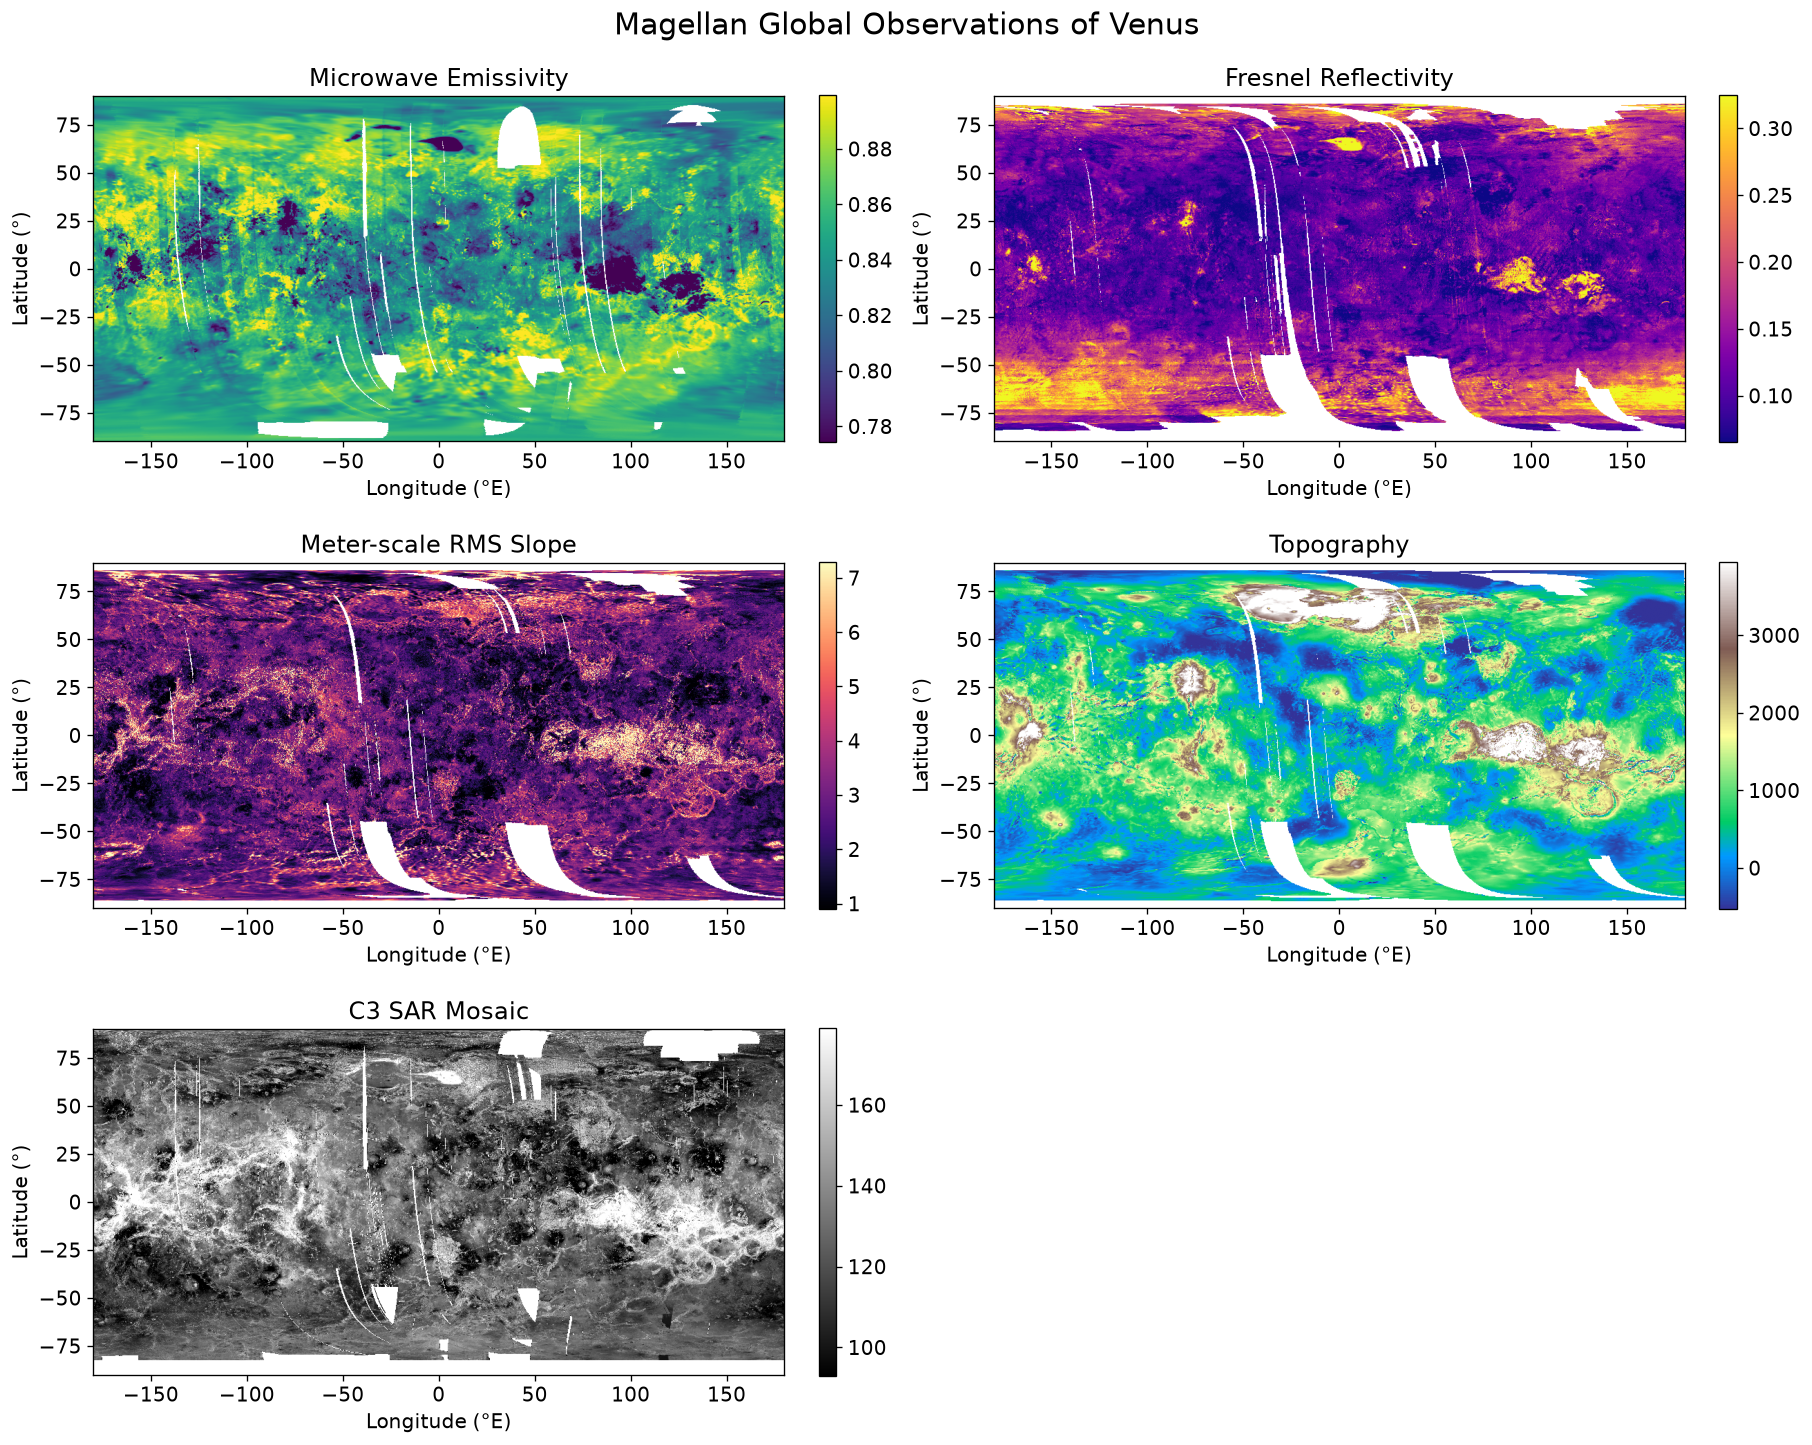

In [8]:
datasets = [
    "Emissivity",
    "Reflectivity",
    "RMS_Slope",
    "Topography",
    "SAR"
]

titles = {
    "Emissivity": "Microwave Emissivity",
    "Reflectivity": "Fresnel Reflectivity",
    "RMS_Slope": "Meter-scale RMS Slope",
    "Topography": "Topography",
    "SAR": "C3 SAR Mosaic"
}

cmaps = {
    "Emissivity": "viridis",
    "Reflectivity": "plasma",
    "RMS_Slope": "magma",
    "Topography": "terrain",
    "SAR": "gray"
}

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 12),
    constrained_layout=True
)

axes = axes.flatten()

for i, name in enumerate(datasets):

    data = read_magellan(
        name,
        out_shape=(500, 1000)
    )

    values = data.compressed()

    vmin, vmax = np.percentile(values, [2, 98])

    im = axes[i].imshow(
        data,
        cmap=cmaps[name],
        vmin=vmin,
        vmax=vmax,
        origin="upper",
        extent=[-180, 180, -90, 90]
    )

    axes[i].set_title(titles[name])
    axes[i].set_xlabel("Longitude (°E)")
    axes[i].set_ylabel("Latitude (°)")

    plt.colorbar(
        im,
        ax=axes[i],
        shrink=0.8
    )

axes[-1].axis("off")

plt.suptitle(
    "Magellan Global Observations of Venus",
    fontsize=18
)

plt.show()

# Extract Alpha Regio and Themis Regio

## Define study regions

In [9]:
REGIONS = {

    "Alpha_Regio": {
        "lon_min": -10,
        "lon_max": 20,
        "lat_min": -35,
        "lat_max": -15
    },

    "Themis_Regio": {
        "lon_min": -90,
        "lon_max": -72,
        "lat_min": -47,
        "lat_max": -35
    }

}

pd.DataFrame(REGIONS).T

,lon_min,lon_max,lat_min,lat_max
Alpha_Regio,-10,20,-35,-15
Themis_Regio,-90,-72,-47,-35


## Create a function to extract a region

In [10]:
def get_region_window(src, region):

    lon_min = region["lon_min"]
    lon_max = region["lon_max"]
    lat_min = region["lat_min"]
    lat_max = region["lat_max"]

    # Longitude to column
    col_min = int(
        np.floor((lon_min + 180) / 360 * (src.width - 1))
    )

    col_max = int(
        np.ceil((lon_max + 180) / 360 * (src.width - 1))
    )

    # Latitude to row (north to south)
    row_min = int(
        np.floor((90 - lat_max) / 180 * (src.height - 1))
    )

    row_max = int(
        np.ceil((90 - lat_min) / 180 * (src.height - 1))
    )

    return Window(
        col_off=col_min,
        row_off=row_min,
        width=col_max - col_min,
        height=row_max - row_min
    )


def extract_region(dataset_name, region_name):

    region = REGIONS[region_name]

    with rasterio.open(FILES[dataset_name]) as src:
        window = get_region_window(src, region)

    data = read_magellan(
        dataset_name,
        window=window
    )

    extent = [
        region["lon_min"],
        region["lon_max"],
        region["lat_min"],
        region["lat_max"]
    ]

    return data, extent

## Plot the five datasets for Alpha Regio

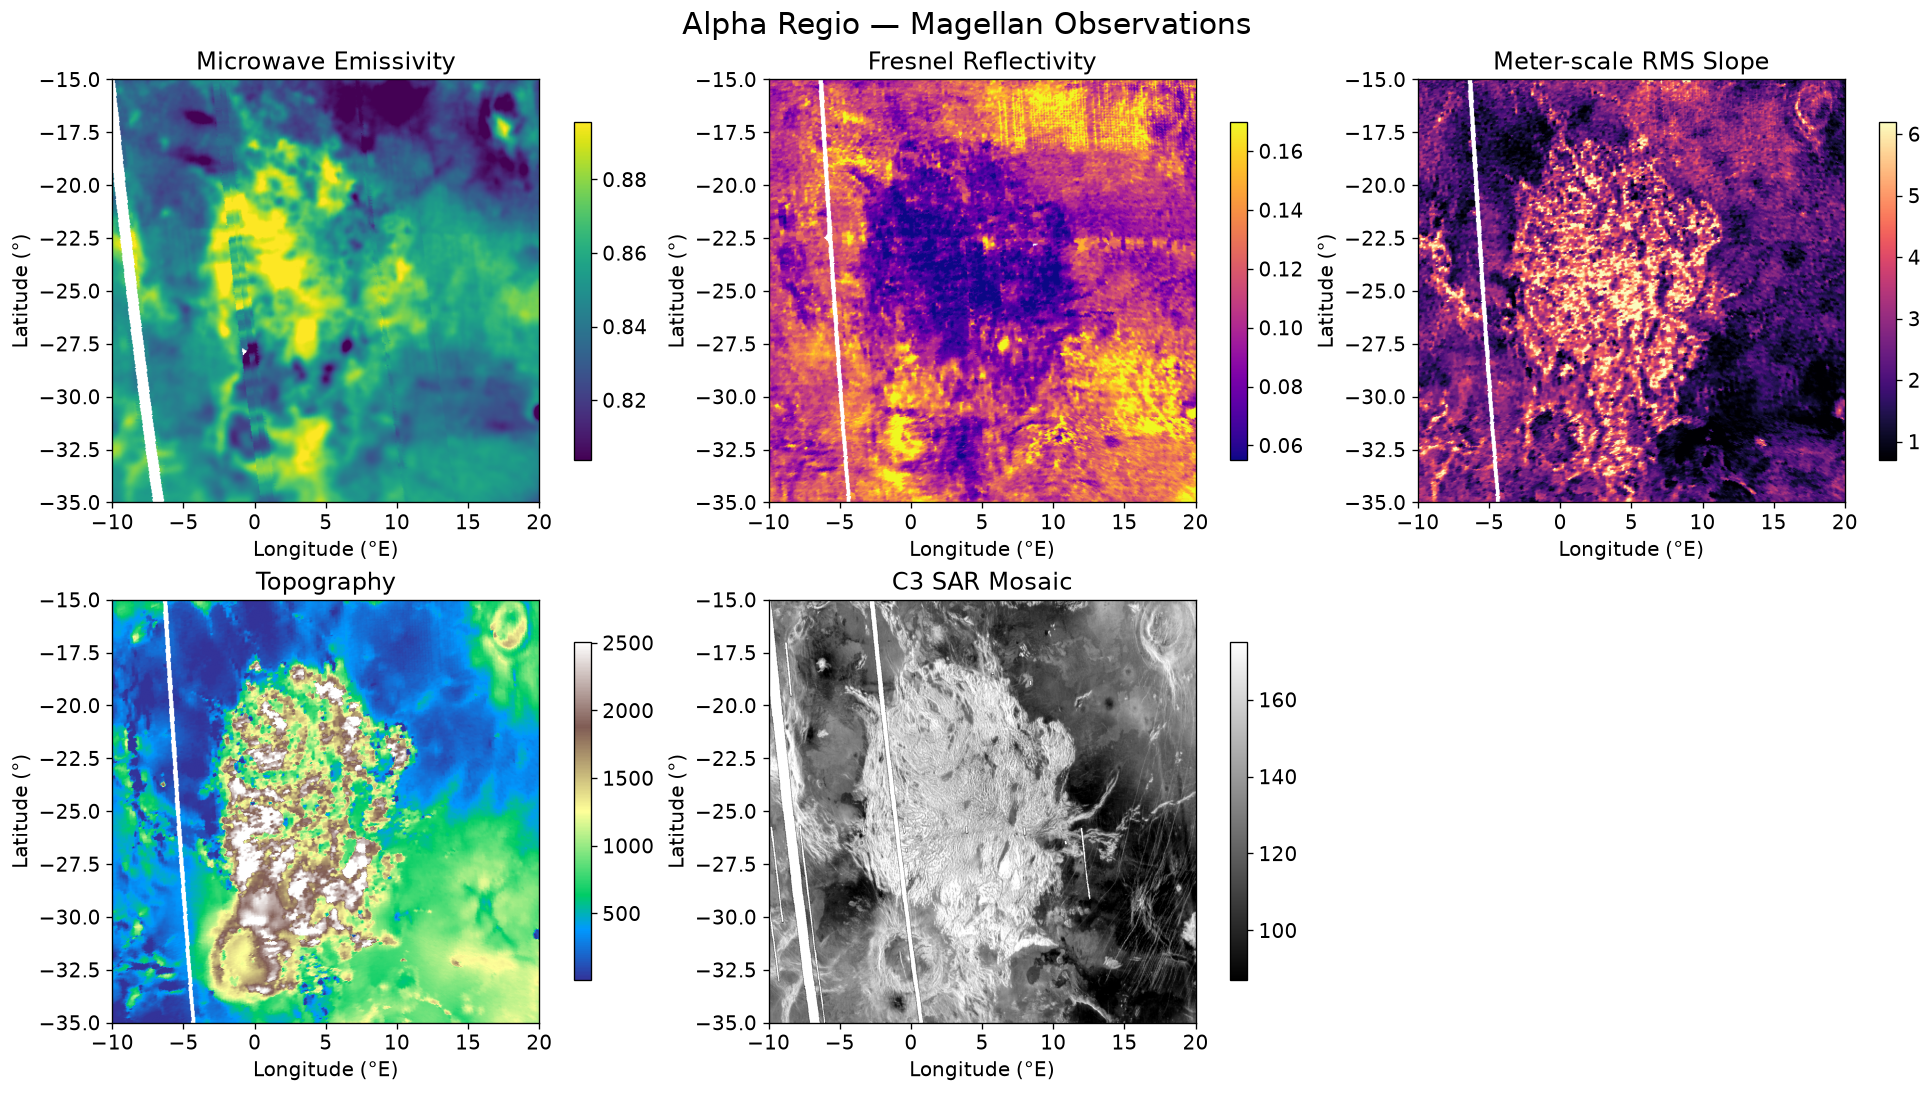

In [11]:
region_name = "Alpha_Regio"

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    constrained_layout=True
)

axes = axes.flatten()

for i, name in enumerate(datasets):

    data, extent = extract_region(
        name,
        region_name
    )

    values = data.compressed()

    if len(values) == 0:
        axes[i].set_title(f"{name}: No valid data")
        continue

    vmin, vmax = np.percentile(values, [2, 98])

    im = axes[i].imshow(
        data,
        extent=extent,
        origin="upper",
        cmap=cmaps[name],
        vmin=vmin,
        vmax=vmax,
        aspect="auto"
    )

    axes[i].set_title(titles[name])
    axes[i].set_xlabel("Longitude (°E)")
    axes[i].set_ylabel("Latitude (°)")

    plt.colorbar(
        im,
        ax=axes[i],
        shrink=0.8
    )

axes[-1].axis("off")

plt.suptitle(
    "Alpha Regio — Magellan Observations",
    fontsize=18
)

plt.show()

## Plot the five datasets for Themis Regio

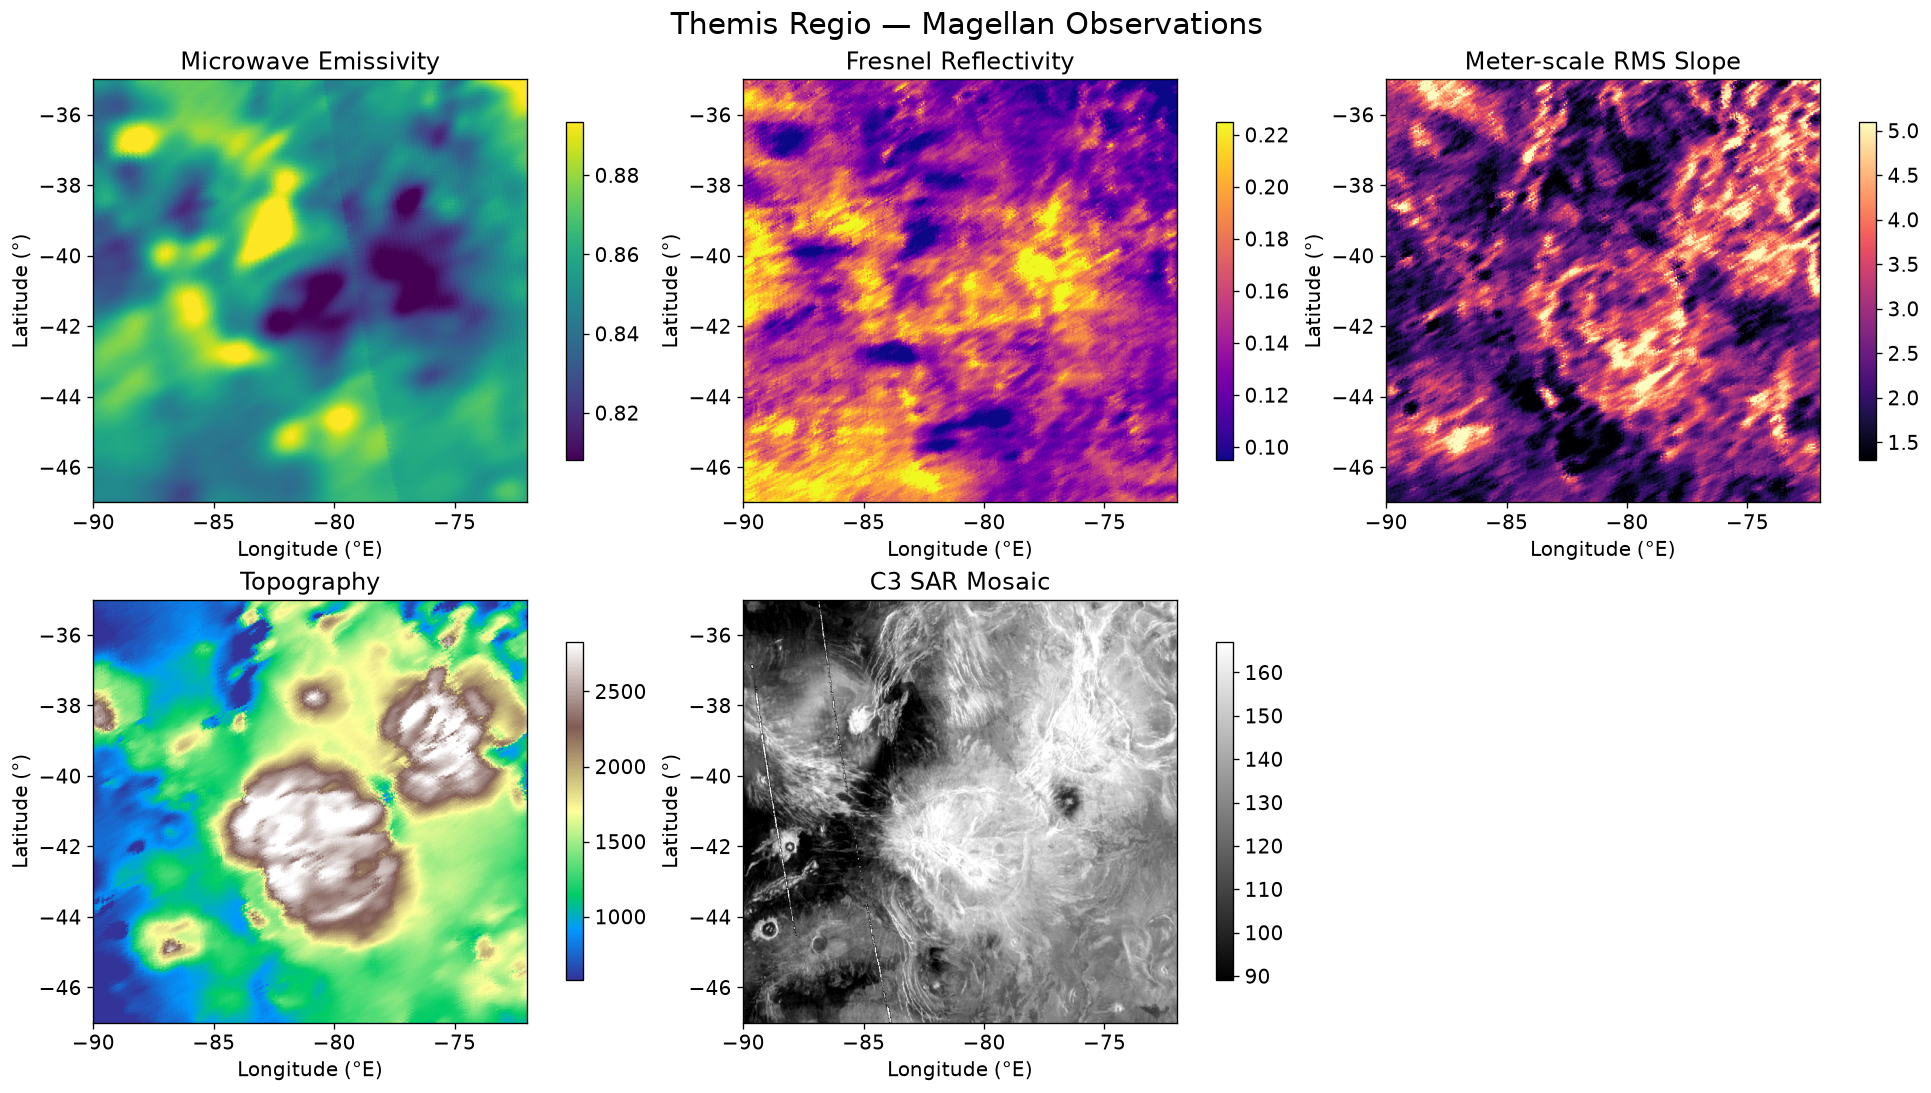

In [12]:
region_name = "Themis_Regio"

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    constrained_layout=True
)

axes = axes.flatten()

for i, name in enumerate(datasets):

    data, extent = extract_region(
        name,
        region_name
    )

    values = data.compressed()

    if len(values) == 0:
        axes[i].set_title(f"{name}: No valid data")
        continue

    vmin, vmax = np.percentile(values, [2, 98])

    im = axes[i].imshow(
        data,
        extent=extent,
        origin="upper",
        cmap=cmaps[name],
        vmin=vmin,
        vmax=vmax,
        aspect="auto"
    )

    axes[i].set_title(titles[name])
    axes[i].set_xlabel("Longitude (°E)")
    axes[i].set_ylabel("Latitude (°)")

    plt.colorbar(
        im,
        ax=axes[i],
        shrink=0.8
    )

axes[-1].axis("off")

plt.suptitle(
    "Themis Regio — Magellan Observations",
    fontsize=18
)

plt.show()